<a href="https://colab.research.google.com/github/atziri01012007-dotcom/detective-senales/blob/main/Detective_de_Senales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# ============================================
# CELDA 1: Importar librerías
# ============================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import pickle
import os

# Semilla para reproducibilidad
np.random.seed(42)

print("Librerías importadas correctamente ✅")

Librerías importadas correctamente ✅


In [8]:
# ============================================
# CELDA 2: Parámetros globales del sistema
# ============================================
fs = 10000          # Frecuencia de muestreo (Hz) -> Nyquist: fs >= 2*fmax
fc = 2000           # Frecuencia portadora (Hz)
Rs = 500            # Tasa de símbolos (baudios) -> 500 símbolos/seg
sps = int(fs / Rs)  # Muestras por símbolo = 20
num_symbols = 50    # Símbolos por señal -> longitud = 50*20 = 1000 muestras

print(f"Frecuencia de muestreo fs = {fs} Hz")
print(f"Frecuencia portadora fc = {fc} Hz")
print(f"Tasa de símbolos Rs = {Rs} baudios")
print(f"Muestras por símbolo = {sps}")
print(f"Longitud de cada señal = {num_symbols * sps} muestras")

Frecuencia de muestreo fs = 10000 Hz
Frecuencia portadora fc = 2000 Hz
Tasa de símbolos Rs = 500 baudios
Muestras por símbolo = 20
Longitud de cada señal = 1000 muestras


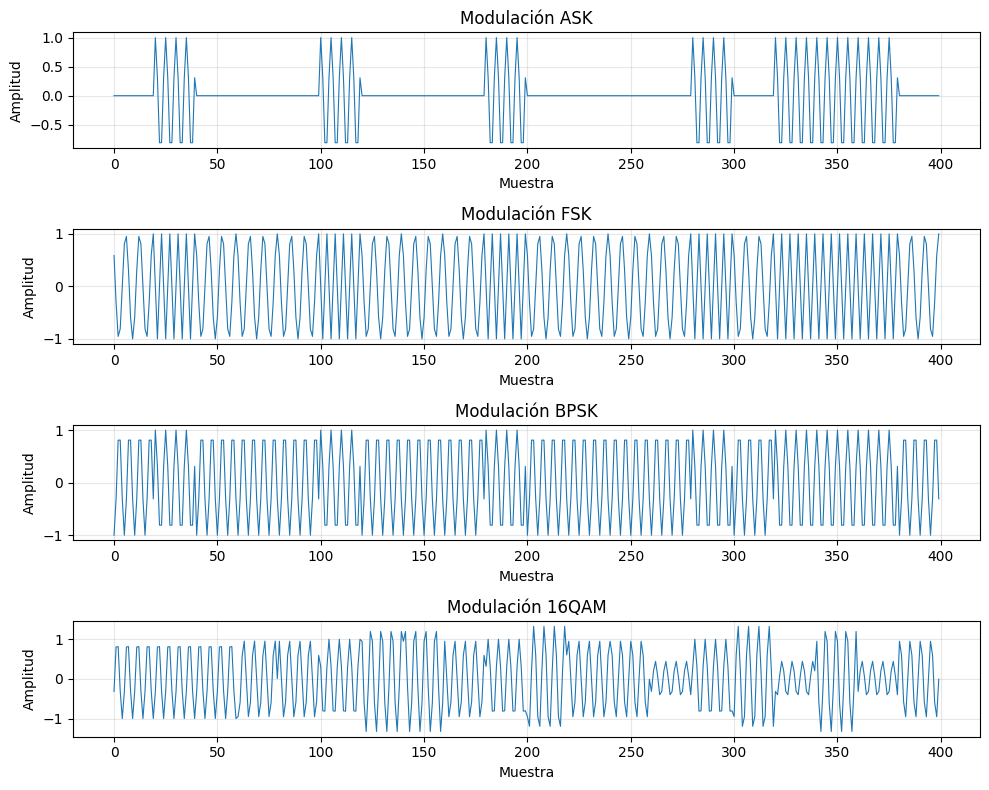

In [9]:
# ============================================
# CELDA 3: Generadores de modulaciones digitales
# ============================================

def generar_bits(n):
    """Genera n bits aleatorios (0/1)."""
    return np.random.randint(0, 2, n)

def upsample(simbolos, sps):
    """Repite cada símbolo 'sps' veces (forma de onda en banda base)."""
    return np.repeat(simbolos, sps)

def generar_ask(bits, fc, fs, sps):
    """ASK / OOK: bit 1 -> amplitud 1, bit 0 -> amplitud 0."""
    t = np.arange(0, len(bits)*sps) / fs
    amplitud = upsample(bits.astype(float), sps)  # 0 o 1
    portadora = np.cos(2*np.pi*fc*t)
    return amplitud * portadora

def generar_fsk(bits, fc, fs, sps, delta_f=500):
    """FSK: bit 1 -> fc + delta_f, bit 0 -> fc - delta_f."""
    frecuencias = np.where(bits == 1, fc + delta_f, fc - delta_f)
    frec_sym = upsample(frecuencias, sps)
    t = np.arange(0, len(bits)*sps) / fs
    # Fase acumulada (integración de la frecuencia instantánea)
    fase = 2*np.pi*np.cumsum(frec_sym)/fs
    return np.cos(fase)

def generar_bpsk(bits, fc, fs, sps):
    """BPSK: bit 1 -> fase 0°, bit 0 -> fase 180°."""
    fases = np.where(bits == 1, 0, np.pi)
    fase_sym = upsample(fases, sps)
    t = np.arange(0, len(bits)*sps) / fs
    return np.cos(2*np.pi*fc*t + fase_sym)

def generar_16qam(bits, fc, fs, sps):
    """16-QAM: agrupa bits en símbolos de 4 bits -> constelación 4x4."""
    # Asegurar que el número de bits sea múltiplo de 4
    n_simbolos = len(bits) // 4
    bits = bits[:n_simbolos*4].reshape(n_simbolos, 4)
    # Mapeo Gray simplificado: 2 bits -> nivel I, 2 bits -> nivel Q
    # Niveles: 00->-3, 01->-1, 10->+1, 11->+3
    def mapear(b2):
        valor = b2[0]*2 + b2[1]
        return np.array([-3, -1, 1, 3])[valor]
    I = np.array([mapear(b[:2]) for b in bits])
    Q = np.array([mapear(b[2:]) for b in bits])
    # Normalizar potencia
    I = I / np.sqrt(10)
    Q = Q / np.sqrt(10)
    # Upsample de I y Q
    I_up = upsample(I, sps)
    Q_up = upsample(Q, sps)
    t = np.arange(0, len(I_up)) / fs
    return I_up*np.cos(2*np.pi*fc*t) - Q_up*np.sin(2*np.pi*fc*t)

# ---- Prueba rápida: graficar una muestra de cada modulación ----
bits_demo = generar_bits(num_symbols * 4)  # bits de sobra para 16-QAM
senales_demo = {
    "ASK":   generar_ask(bits_demo[:num_symbols], fc, fs, sps),
    "FSK":   generar_fsk(bits_demo[:num_symbols], fc, fs, sps),
    "BPSK":  generar_bpsk(bits_demo[:num_symbols], fc, fs, sps),
    "16QAM": generar_16qam(bits_demo, fc, fs, sps),
}

fig, axes = plt.subplots(4, 1, figsize=(10, 8))
for ax, (nombre, senal) in zip(axes, senales_demo.items()):
    ax.plot(senal[:400], linewidth=0.8)
    ax.set_title(f"Modulación {nombre}")
    ax.set_xlabel("Muestra")
    ax.set_ylabel("Amplitud")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# ============================================
# CELDA 4: Generar el dataset
# ============================================
N_MUESTRAS = 1000   # mínimo requerido por el proyecto
LONGITUD = num_symbols * sps  # 1000 muestras por señal

# Diccionario de generadores
generadores = {
    "ASK":   lambda b: generar_ask(b[:num_symbols], fc, fs, sps),
    "FSK":   lambda b: generar_fsk(b[:num_symbols], fc, fs, sps),
    "BPSK":  lambda b: generar_bpsk(b[:num_symbols], fc, fs, sps),
    "16QAM": lambda b: generar_16qam(b, fc, fs, sps),
}
etiquetas = list(generadores.keys())  # ['ASK','FSK','BPSK','16QAM']
mapa_etiquetas = {nombre: idx for idx, nombre in enumerate(etiquetas)}

X = []  # señales
y = []  # etiquetas numéricas

for nombre, gen in generadores.items():
    for _ in range(N_MUESTRAS):
        bits = generar_bits(num_symbols * 4)  # suficientes para todos
        senal = gen(bits)
        # Asegurar longitud exacta
        senal = senal[:LONGITUD]
        if len(senal) < LONGITUD:
            senal = np.pad(senal, (0, LONGITUD - len(senal)))
        X.append(senal)
        y.append(mapa_etiquetas[nombre])

X = np.array(X)
y = np.array(y)

print(f"Forma de X: {X.shape}")   # (4000, 1000)
print(f"Forma de y: {y.shape}")   # (4000,)
print(f"Clases: {etiquetas}")
print(f"Distribución: {np.bincount(y)}")

Forma de X: (4000, 1000)
Forma de y: (4000,)
Clases: ['ASK', 'FSK', 'BPSK', '16QAM']
Distribución: [1000 1000 1000 1000]


SNR = -10 dB generado. Forma: (4000, 1000)
SNR =  -5 dB generado. Forma: (4000, 1000)
SNR =   0 dB generado. Forma: (4000, 1000)
SNR =   5 dB generado. Forma: (4000, 1000)
SNR =  10 dB generado. Forma: (4000, 1000)
SNR =  15 dB generado. Forma: (4000, 1000)
SNR =  20 dB generado. Forma: (4000, 1000)


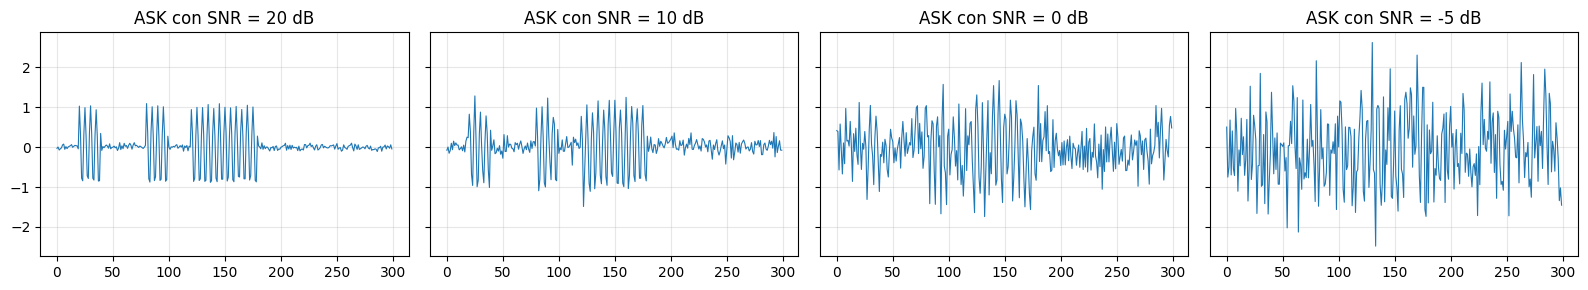

In [11]:
# ============================================
# CELDA 5: Función AWGN
# ============================================
def agregar_awgn(senal, snr_db):
    """
    Añade Ruido Gaussiano Blanco Aditivo a una señal.
    snr_db: Relación Señal-Ruido en dB.
    """
    potencia_senal = np.mean(senal**2)
    potencia_ruido = potencia_senal / (10**(snr_db/10))
    ruido = np.random.normal(0, np.sqrt(potencia_ruido), len(senal))
    return senal + ruido

# Niveles de SNR de prueba (para Fase 3)
SNR_NIVELES = [-10, -5, 0, 5, 10, 15, 20]  # dB

# Generamos versiones con ruido para cada nivel
X_ruidoso = {}   # dict: snr -> array (4000, 1000)
for snr in SNR_NIVELES:
    X_ruidoso[snr] = np.array([agregar_awgn(s, snr) for s in X])
    print(f"SNR = {snr:>3} dB generado. Forma: {X_ruidoso[snr].shape}")

# Visualización: una señal ASK limpia vs con ruido
idx = 0  # primera señal (ASK)
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, snr in zip(axes, [20, 10, 0, -5]):
    ax.plot(X_ruidoso[snr][idx][:300], linewidth=0.8)
    ax.set_title(f"ASK con SNR = {snr} dB")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# ============================================
# CELDA 6: Train/Test split
# ============================================
# Usamos el dataset con SNR medio (ej. 10 dB) como base principal
SNR_BASE = 10

X_train, X_test, y_train, y_test = train_test_split(
    X_ruidoso[SNR_BASE], y,
    test_size=0.2,
    random_state=42,
    stratify=y   # mantiene la proporción de clases
)

print("=== División de datos (SNR = 10 dB) ===")
print(f"Entrenamiento: X={X_train.shape}, y={y_train.shape}")
print(f"Prueba:        X={X_test.shape}, y={y_test.shape}")
print(f"Distribución train: {np.bincount(y_train)}")
print(f"Distribución test:  {np.bincount(y_test)}")

=== División de datos (SNR = 10 dB) ===
Entrenamiento: X=(3200, 1000), y=(3200,)
Prueba:        X=(800, 1000), y=(800,)
Distribución train: [800 800 800 800]
Distribución test:  [200 200 200 200]


In [13]:
# ============================================
# CELDA 7: Guardar dataset para Semana 2
# ============================================
# Guardamos el dataset limpio y el ruidoso (para Fase 3)
np.savez_compressed("dataset_senales.npz",
                    X=X, y=y,
                    X_train=X_train, X_test=X_test,
                    y_train=y_train, y_test=y_test,
                    etiquetas=np.array(etiquetas),
                    SNR_NIVELES=np.array(SNR_NIVELES),
                    SNR_BASE=SNR_BASE)

# Dataset ruidoso aparte (uno por SNR) para la prueba de estrés
for snr in SNR_NIVELES:
    np.savez_compressed(f"dataset_snr_{snr}dB.npz",
                        X=X_ruidoso[snr], y=y)

print("✅ Dataset guardado: dataset_senales.npz")
print("✅ Datasets por SNR guardados")

# Si estás en Colab, descarga:
# from google.colab import files
# files.download('dataset_senales.npz')

✅ Dataset guardado: dataset_senales.npz
✅ Datasets por SNR guardados


In [14]:
# ============================================
# CELDA 1: Importar librerías y cargar dataset
# ============================================
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pickle

# Semilla para reproducibilidad
tf.random.set_seed(42)
np.random.seed(42)

# --- Cargar dataset guardado en Semana 1 ---
data = np.load("dataset_senales.npz", allow_pickle=True)
X_train = data["X_train"]
X_test  = data["X_test"]
y_train = data["y_train"]
y_test  = data["y_test"]
etiquetas = list(data["etiquetas"])

print("Dataset cargado ✅")
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Clases: {etiquetas}")
print(f"Distribución train: {np.bincount(y_train)}")

Dataset cargado ✅
X_train: (3200, 1000) | X_test: (800, 1000)
Clases: [np.str_('ASK'), np.str_('FSK'), np.str_('BPSK'), np.str_('16QAM')]
Distribución train: [800 800 800 800]


In [15]:
# ============================================
# CELDA 2: Ajustar forma para Conv1D
# ============================================
# (3200, 1000) -> (3200, 1000, 1)
X_train_cnn = X_train[..., np.newaxis]
X_test_cnn  = X_test[..., np.newaxis]

# Etiquetas a one-hot para categorical_crossentropy
num_clases = len(etiquetas)
y_train_oh = keras.utils.to_categorical(y_train, num_clases)
y_test_oh  = keras.utils.to_categorical(y_test, num_clases)

print(f"X_train_cnn: {X_train_cnn.shape}")
print(f"y_train_oh:  {y_train_oh.shape}")
print(f"Número de clases: {num_clases}")

X_train_cnn: (3200, 1000, 1)
y_train_oh:  (3200, 4)
Número de clases: 4


In [16]:
# ============================================
# CELDA 3: Definir la arquitectura CNN 1D
# ============================================
def crear_modelo_cnn(longitud_entrada, num_clases):
    modelo = keras.Sequential([
        layers.Input(shape=(longitud_entrada, 1)),

        # --- Bloque convolucional 1 ---
        layers.Conv1D(filters=32, kernel_size=7, activation='relu', padding='same'),
        layers.MaxPooling1D(pool_size=2),

        # --- Bloque convolucional 2 ---
        layers.Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
        layers.MaxPooling1D(pool_size=2),

        # --- Bloque convolucional 3 (opcional, mejora precisión) ---
        layers.Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling1D(pool_size=2),

        # --- Clasificador ---
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),               # regularización
        layers.Dense(num_clases, activation='softmax')  # 4 neuronas
    ])
    return modelo

modelo = crear_modelo_cnn(longitud_entrada=X_train_cnn.shape[1],
                          num_clases=num_clases)

modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1000, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 500, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 500, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 250, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 250, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 125, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,024,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,047,556 (4.00 MB)

 Trainable params: 1,047,556 (4.00 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# ============================================
# CELDA 4: Compilar el modelo
# ============================================
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',   # multiclase con one-hot
    metrics=['accuracy']
)

print("Modelo compilado ✅")

Modelo compilado ✅


In [22]:
# ============================================
# CELDA 5: Entrenar el modelo
# ============================================
EPOCHS = 30
BATCH_SIZE = 64

# Callbacks útiles
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6
    )
]

historial = modelo.fit(
    X_train_cnn, y_train_oh,
    validation_split=0.15,     # 15% del train para validación
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 11s 208ms/step - accuracy: 0.7294 - loss: 0.6147 - val_accuracy: 1.0000 - val_loss: 0.0084 - learning_rate: 0.0010
Epoch 2/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 8s 164ms/step - accuracy: 0.9974 - loss: 0.0137 - val_accuracy: 1.0000 - val_loss: 1.7962e-04 - learning_rate: 0.0010
Epoch 3/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 9s 208ms/step - accuracy: 0.9996 - loss: 0.0023 - val_accuracy: 1.0000 - val_loss: 1.5644e-05 - learning_rate: 0.0010
Epoch 4/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 10s 199ms/step - accuracy: 1.0000 - loss: 0.0023 - val_accuracy: 1.0000 - val_loss: 1.0740e-05 - learning_rate: 0.0010
Epoch 5/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 7s 161ms/step - accuracy: 0.9996 - loss: 0.0025 - val_accuracy: 1.0000 - val_loss: 1.1248e-05 - learning_rate: 0.0010
Epoch 6/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 9s 205ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 1.0000 - val_loss: 3.4791e-06 - learning_rate: 0.0010
Epoch 7/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 7s 158ms/step - accuracy: 1.

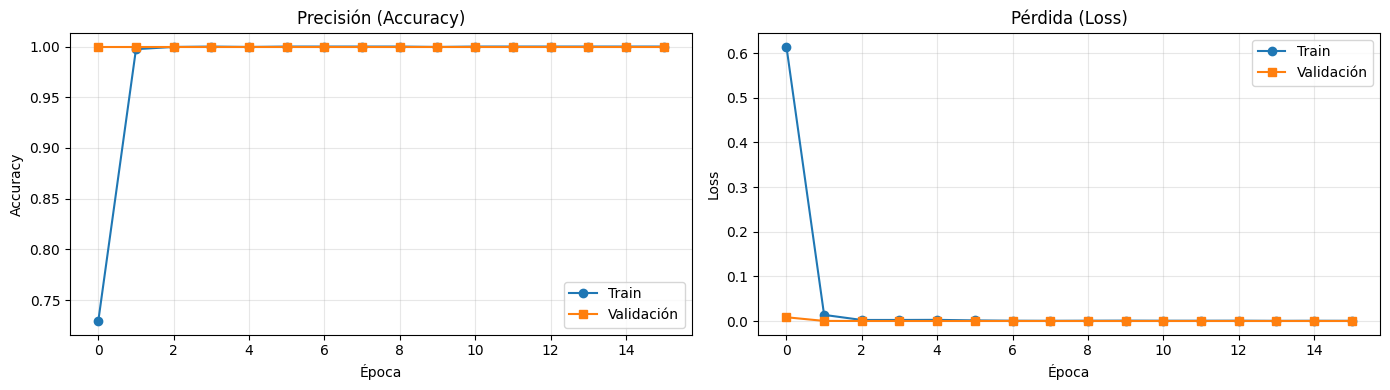

In [23]:
# ============================================
# CELDA 6: Curvas de precisión y pérdida
# ============================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Precisión
axes[0].plot(historial.history['accuracy'], label='Train', marker='o')
axes[0].plot(historial.history['val_accuracy'], label='Validación', marker='s')
axes[0].set_title('Precisión (Accuracy)')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Pérdida
axes[1].plot(historial.history['loss'], label='Train', marker='o')
axes[1].plot(historial.history['val_loss'], label='Validación', marker='s')
axes[1].set_title('Pérdida (Loss)')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# ============================================
# CELDA 7: Evaluación en test (SNR = 10 dB)
# ============================================
loss_test, acc_test = modelo.evaluate(X_test_cnn, y_test_oh, verbose=0)
print(f"📊 Pérdida en test:  {loss_test:.4f}")
print(f"📊 Precisión en test: {acc_test*100:.2f}%")

📊 Pérdida en test:  0.0000
📊 Precisión en test: 100.00%


In [25]:
# ============================================
# CELDA 8: Guardar modelo entrenado
# ============================================
# Formato nativo Keras (recomendado)
modelo.save("modelo_detective_senales.keras")

# También guardamos el historial para la Fase 4 (reporte)
with open("historial_entrenamiento.pkl", "wb") as f:
    pickle.dump(historial.history, f)

print("✅ Modelo guardado: modelo_detective_senales.keras")
print("✅ Historial guardado: historial_entrenamiento.pkl")

# Descargar si estás en Colab:
# from google.colab import files
# files.download('modelo_detective_senales.keras')

✅ Modelo guardado: modelo_detective_senales.keras
✅ Historial guardado: historial_entrenamiento.pkl


In [26]:
# ============================================
# CELDA 1: Importar y cargar todo lo de semanas 1 y 2
# ============================================
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import pickle

# --- Cargar modelo entrenado (Semana 2) ---
modelo = keras.models.load_model("modelo_detective_senales.keras")

# --- Cargar dataset base (Semana 1) ---
data = np.load("dataset_senales.npz", allow_pickle=True)
X_test    = data["X_test"]
y_test    = data["y_test"]
etiquetas = list(data["etiquetas"])
SNR_NIVELES = list(data["SNR_NIVELES"])
SNR_BASE = int(data["SNR_BASE"])
num_clases = len(etiquetas)

# --- Cargar datasets ruidosos por SNR (Semana 1) ---
X_ruidoso = {}
y_ruidoso = {}
for snr in SNR_NIVELES:
    d = np.load(f"dataset_snr_{snr}dB.npz", allow_pickle=True)
    X_ruidoso[snr] = d["X"]
    y_ruidoso[snr] = d["y"]

print("✅ Modelo y datos cargados")
print(f"Clases: {etiquetas}")
print(f"Niveles SNR: {SNR_NIVELES} dB")
print(f"Test set (SNR={SNR_BASE} dB): {X_test.shape}")

✅ Modelo y datos cargados
Clases: [np.str_('ASK'), np.str_('FSK'), np.str_('BPSK'), np.str_('16QAM')]
Niveles SNR: [np.int64(-10), np.int64(-5), np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20)] dB
Test set (SNR=10 dB): (800, 1000)


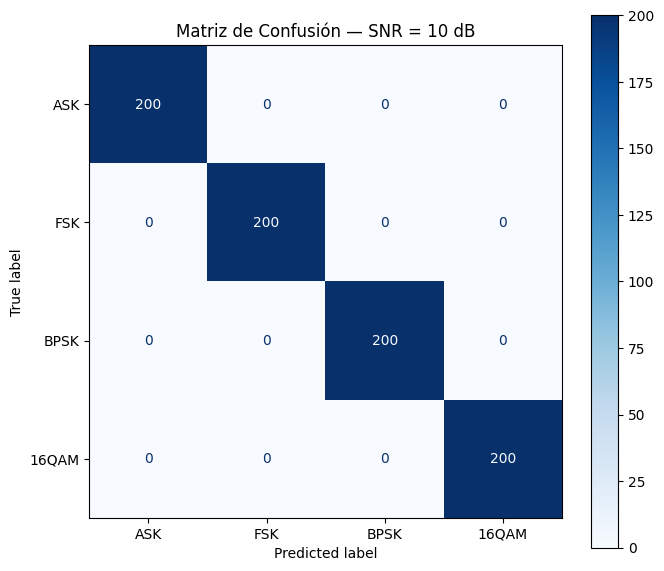


=== Reporte de clasificación ===
              precision    recall  f1-score   support

         ASK      1.000     1.000     1.000       200
         FSK      1.000     1.000     1.000       200
        BPSK      1.000     1.000     1.000       200
       16QAM      1.000     1.000     1.000       200

    accuracy                          1.000       800
   macro avg      1.000     1.000     1.000       800
weighted avg      1.000     1.000     1.000       800



In [27]:
# ============================================
# CELDA 2: Matriz de confusión (SNR = 10 dB)
# ============================================
# Preparar entradas
X_test_cnn = X_test[..., np.newaxis]

# Predicciones
y_pred_probs = modelo.predict(X_test_cnn, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

# Visualizar
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=etiquetas)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=True)
ax.set_title(f"Matriz de Confusión — SNR = {SNR_BASE} dB")
plt.tight_layout()
plt.show()

# Reporte de clasificación detallado
print("\n=== Reporte de clasificación ===")
print(classification_report(y_test, y_pred, target_names=etiquetas, digits=3))

In [28]:
# ============================================
# CELDA 3: Analizar confusiones entre clases
# ============================================
print("=== Análisis de confusiones (fuera de la diagonal) ===\n")
for i, real in enumerate(etiquetas):
    for j, pred in enumerate(etiquetas):
        if i != j and cm[i, j] > 0:
            print(f"  {real:>6} → {pred:<6}: {cm[i, j]:>3} errores")

=== Análisis de confusiones (fuera de la diagonal) ===



In [29]:
# ============================================
# CELDA 4: Evaluar el modelo en todos los niveles de SNR
# ============================================
resultados = {}   # dict: snr -> accuracy
predicciones = {}

print("Evaluando modelo en distintos niveles de ruido...\n")
for snr in SNR_NIVELES:
    X_snr = X_ruidoso[snr][..., np.newaxis]
    y_snr = y_ruidoso[snr]

    y_prob = modelo.predict(X_snr, verbose=0)
    y_pred_snr = np.argmax(y_prob, axis=1)

    acc = np.mean(y_pred_snr == y_snr)
    resultados[snr] = acc
    predicciones[snr] = y_pred_snr

    print(f"SNR = {snr:>4} dB  →  Accuracy = {acc*100:>6.2f}%")

Evaluando modelo en distintos niveles de ruido...

SNR =  -10 dB  →  Accuracy =  25.00%
SNR =   -5 dB  →  Accuracy =  46.60%
SNR =    0 dB  →  Accuracy =  94.77%
SNR =    5 dB  →  Accuracy = 100.00%
SNR =   10 dB  →  Accuracy = 100.00%
SNR =   15 dB  →  Accuracy = 100.00%
SNR =   20 dB  →  Accuracy = 100.00%


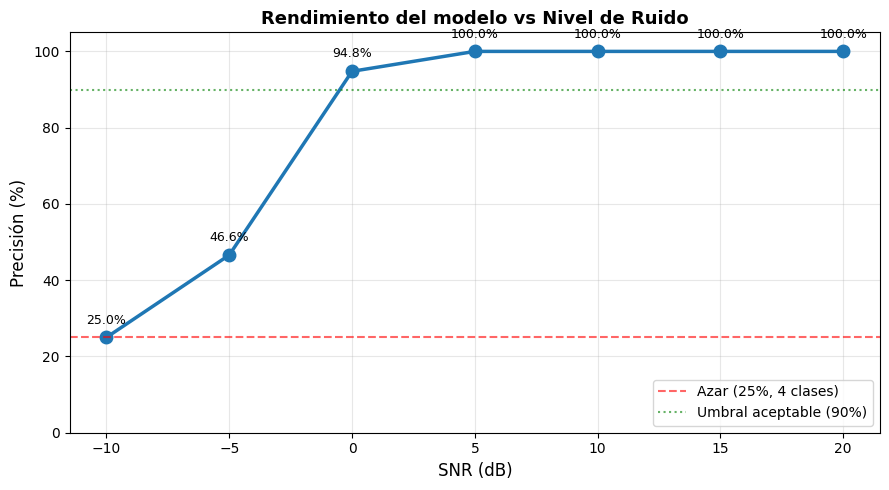

In [30]:
# ============================================
# CELDA 5: Curva de precisión vs SNR
# ============================================
snrs = sorted(resultados.keys())
accs = [resultados[s]*100 for s in snrs]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(snrs, accs, marker='o', linewidth=2.5, markersize=9, color='#1f77b4')
ax.axhline(y=25, color='red', linestyle='--', alpha=0.6,
           label='Azar (25%, 4 clases)')
ax.axhline(y=90, color='green', linestyle=':', alpha=0.6,
           label='Umbral aceptable (90%)')
ax.set_xlabel("SNR (dB)", fontsize=12)
ax.set_ylabel("Precisión (%)", fontsize=12)
ax.set_title("Rendimiento del modelo vs Nivel de Ruido", fontsize=13, weight='bold')
ax.grid(True, alpha=0.3)
ax.legend(loc='lower right')
ax.set_ylim(0, 105)

# Anotar cada punto
for s, a in zip(snrs, accs):
    ax.annotate(f"{a:.1f}%", (s, a), textcoords="offset points",
                xytext=(0, 10), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [31]:
# ============================================
# CELDA 6: ¿En qué SNR el modelo se vuelve "ciego"?
# ============================================
UMBRAL_CIEGO = 50   # debajo del 50% consideramos "ciego"

print("=== Análisis del punto de ceguera ===\n")
punto_ciego = None
for snr in snrs:
    acc = resultados[snr] * 100
    estado = "🔴 CIEGO" if acc < UMBRAL_CIEGO else "🟢 FUNCIONAL"
    print(f"SNR = {snr:>4} dB → {acc:>5.1f}%  {estado}")
    if acc < UMBRAL_CIEGO and punto_ciego is None:
        punto_ciego = snr

print(f"\n→ El modelo se vuelve 'ciego' (< {UMBRAL_CIEGO}%) en SNR ≤ {punto_ciego} dB")
print(f"→ En SNR ≥ 0 dB el modelo es confiable (>{resultados[0]*100:.0f}% de acierto)")

=== Análisis del punto de ceguera ===

SNR =  -10 dB →  25.0%  🔴 CIEGO
SNR =   -5 dB →  46.6%  🔴 CIEGO
SNR =    0 dB →  94.8%  🟢 FUNCIONAL
SNR =    5 dB → 100.0%  🟢 FUNCIONAL
SNR =   10 dB → 100.0%  🟢 FUNCIONAL
SNR =   15 dB → 100.0%  🟢 FUNCIONAL
SNR =   20 dB → 100.0%  🟢 FUNCIONAL

→ El modelo se vuelve 'ciego' (< 50%) en SNR ≤ -10 dB
→ En SNR ≥ 0 dB el modelo es confiable (>95% de acierto)


=== Recall por modulación a SNR = 0 dB ===

    BPSK:  79.1%  (791/1000 aciertos)
     ASK: 100.0%  (1000/1000 aciertos)
     FSK: 100.0%  (1000/1000 aciertos)
   16QAM: 100.0%  (1000/1000 aciertos)

→ Modulación MÁS DIFÍCIL de clasificar: BPSK


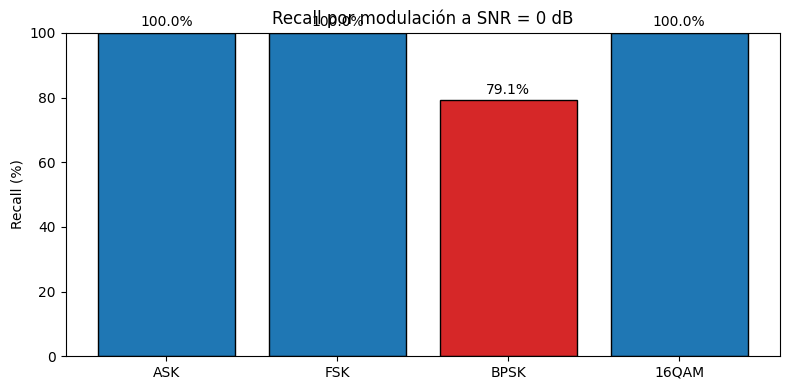

In [32]:
# ============================================
# CELDA 7: ¿Qué modulación es más difícil de clasificar?
# ============================================
# Matriz de confusión en el SNR más bajo no trivial (ej. 0 dB)
SNR_ANALISIS = 0
cm_bajo = confusion_matrix(y_ruidoso[SNR_ANALISIS], predicciones[SNR_ANALISIS])

# Precisión (recall) por clase
recalls = cm_bajo.diagonal() / cm_bajo.sum(axis=1)

print(f"=== Recall por modulación a SNR = {SNR_ANALISIS} dB ===\n")
orden = np.argsort(recalls)   # de peor a mejor
for idx in orden:
    print(f"  {etiquetas[idx]:>6}: {recalls[idx]*100:>5.1f}%  "
          f"({cm_bajo[idx, idx]}/{cm_bajo[idx].sum()} aciertos)")

peor = etiquetas[orden[0]]
print(f"\n→ Modulación MÁS DIFÍCIL de clasificar: {peor}")

# Gráfico de barras comparativo
fig, ax = plt.subplots(figsize=(8, 4))
colores = ['#d62728' if etiquetas[i]==peor else '#1f77b4' for i in range(num_clases)]
bars = ax.bar(etiquetas, recalls*100, color=colores, edgecolor='black')
ax.set_ylabel("Recall (%)")
ax.set_title(f"Recall por modulación a SNR = {SNR_ANALISIS} dB")
ax.set_ylim(0, 100)
for bar, r in zip(bars, recalls):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
            f"{r*100:.1f}%", ha='center', fontsize=10)
plt.tight_layout()
plt.show()

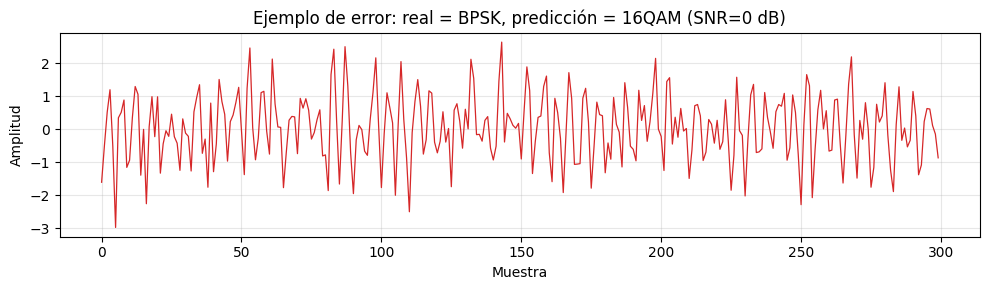

In [33]:
# ============================================
# CELDA 8: Ver visualmente los errores típicos
# ============================================
# Elegir la modulación más difícil y mostrar una señal mal clasificada
idx_peor = orden[0]
errores = np.where((y_ruidoso[SNR_ANALISIS] == idx_peor) &
                   (predicciones[SNR_ANALISIS] != idx_peor))[0]

if len(errores) > 0:
    idx_error = errores[0]
    senal_err = X_ruidoso[SNR_ANALISIS][idx_error]
    real = etiquetas[y_ruidoso[SNR_ANALISIS][idx_error]]
    predicha = etiquetas[predicciones[SNR_ANALISIS][idx_error]]

    plt.figure(figsize=(10, 3))
    plt.plot(senal_err[:300], linewidth=0.9, color='#d62728')
    plt.title(f"Ejemplo de error: real = {real}, predicción = {predicha} "
              f"(SNR={SNR_ANALISIS} dB)")
    plt.xlabel("Muestra")
    plt.ylabel("Amplitud")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [34]:
# ============================================
# CELDA 9: Guardar resultados para el reporte
# ============================================
# Guardar todas las métricas y matrices en un diccionario
resultados_export = {
    "snr_niveles": snrs,
    "accuracy_por_snr": [resultados[s] for s in snrs],
    "confusion_matrix_base": cm.tolist(),
    "confusion_matrix_0dB": cm_bajo.tolist(),
    "recalls_por_clase_0dB": recalls.tolist(),
    "etiquetas": etiquetas,
    "peor_modulacion": peor,
    "punto_ciego_dB": punto_ciego,
}

with open("resultados_semana3.pkl", "wb") as f:
    pickle.dump(resultados_export, f)

# También guardar las gráficas como imágenes (para el reporte PDF)
# Re-ejecuta las celdas 2, 5, 7 agregando plt.savefig(...) si quieres exportarlas
plt.savefig("grafica_accuracy_vs_snr.png", dpi=150, bbox_inches='tight')

print("✅ Resultados guardados: resultados_semana3.pkl")
print("✅ Gráfica exportada: grafica_accuracy_vs_snr.png")

✅ Resultados guardados: resultados_semana3.pkl
✅ Gráfica exportada: grafica_accuracy_vs_snr.png


<Figure size 640x480 with 0 Axes>